# Text Classification — Naive Bayes & Logistic Regression

Pipeline: **Load Data → Preprocessing → Model → Evaluation → Test**, built for both a Naive Bayes classifier and a Logistic Regression classifier on the same TF-IDF features, so their results can be compared directly.

In [6]:
# run on terminal to download
#python -m spacy download en_core_web_sm

In [7]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import string
import nltk

from nltk.corpus import stopwords
nltk.download('stopwords')
import spacy
nlp = spacy.load("en_core_web_sm")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\fagr\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 1. Load Data

In [11]:
!pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   -------------------- ------------------- 1/2 [kagglehub]
   -------------------- ------------------- 1/2 [kagglehub]
   ---------------------------------------- 2/2 [kagglehub]



In [12]:
# https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Path to dataset files:", path)

C:\Users\fagr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 25.7M/25.7M [00:07<00:00, 3.56MB/s]

Extracting files...


Path to dataset files: C:\Users\fagr\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1


In [18]:
# -------------------------------
# Load dataset
# Expected columns: 'review' (text) and 'sentiment' ('positive' / 'negative')
# -------------------------------
df = pd.read_csv(r"C:\Users\fagr\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1\IMDB Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 2. Data Preprocessing

Same cleaning pipeline for both models, so the comparison between them is fair: label encoding → strip HTML tags → strip URLs → lowercase → strip punctuation → remove stopwords → lemmatize.

In [22]:
def data_read():

    """function to read data into pandas dataframe,
    further convert sentiment column into numerical values"""

    global df

    df = pd.read_csv(r"C:\Users\fagr\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1\IMDB Dataset.csv")
    df['sentiment'] = df['sentiment'].apply(lambda x: 1 if x == 'positive' else 0)

def html_tag_remover():

    """function to remove html tags using regex,
    and store a copy of dataframe in variable"""

    global df_removed_tag

    df['review'] = df['review'].str.replace(r'<[^<>]*>', '', regex=True)
    df_removed_tag = df

def url_remover():

    """function to remove url using regex,
    and store a copy of dataframe in variable"""

    global df_removed_url

    df['review'] = df['review'].str.replace(r'https?://\S+|www\.\S+', '', regex=True)
    df_removed_url = df

def lowercase():

    """function to convert review into lowercase,
    and store a copy of dataframe in variable"""

    global df_lower

    df['review'] = df['review'].str.lower()
    df_lower = df

def punctuation_remover():

    """function to remove punctuation using regex,
    and store a copy of dataframe in variable"""

    global df_punc_removed

    df['review'] = df['review'].str.replace('[{}]'.format(string.punctuation), '', regex=True)
    df_punc_removed = df

def stopword_remover():

    """function to remove stopwords,
    and store a copy of dataframe in variable"""

    global df_stopword_removed

    stop_words = set(stopwords.words('english'))
    df['review'] = df['review'].apply(lambda x: ' '.join([word for word in x.split() if word not in stop_words]))
    df_stopword_removed = df

def lemmatize_text():

    """function to lemmatize reviews using SpaCy"""
    global df_lemmatized

    def lemmatize_sentence(sentence):
        doc = nlp(sentence)
        return " ".join([token.lemma_ for token in doc])

    df['review'] = df['review'].apply(lemmatize_sentence)
    df_lemmatized = df

In [23]:
def data_preprocess():

    data_read()
    html_tag_remover()
    url_remover()
    lowercase()
    punctuation_remover()
    stopword_remover()
    lemmatize_text()

    return

In [24]:
data_preprocess()
df.head()

,review,sentiment
0,one reviewer mention watch 1 oz episode you ll...,1
1,wonderful little production filming technique ...,1
2,think wonderful way spend time hot summer week...,1
3,basically there s family little boy jake think...,0
4,petter matteis love time money visually stunni...,1


## 3. Train / Test Split & TF-IDF Vectorization

Both models share the exact same train/test split and the exact same TF-IDF features — only the classifier on top changes.

In [25]:
"""split the dataset
75% for training
25% for testing"""

train, test = train_test_split(df, test_size=0.25, random_state=42)

X_train, y_train = train['review'], train['sentiment']
X_test, y_test = test['review'], test['sentiment']

In [26]:
tfidf = TfidfVectorizer()
x_train_vector = tfidf.fit_transform(X_train)
x_test_vector = tfidf.transform(X_test)

## 4. Model 1 — Naive Bayes

In [27]:
multi_clf = MultinomialNB()
multi_clf.fit(x_train_vector, y_train.values)

predict_NB = multi_clf.predict(x_test_vector)

### Naive Bayes — Evaluation

Naive Bayes — Classification Report: 

               precision    recall  f1-score   support

           0       0.84      0.88      0.86      6157
           1       0.88      0.84      0.86      6343

    accuracy                           0.86     12500
   macro avg       0.86      0.86      0.86     12500
weighted avg       0.86      0.86      0.86     12500

Naive Bayes — Accuracy: 

 0.86024


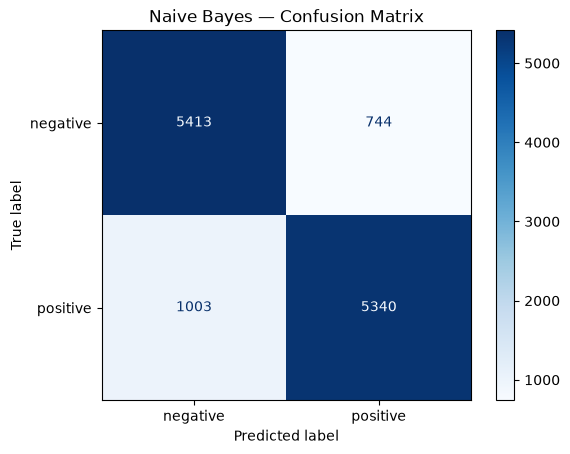

In [28]:
print("Naive Bayes — Classification Report: \n\n", classification_report(y_test, predict_NB))
print("Naive Bayes — Accuracy: \n\n", accuracy_score(y_test, predict_NB))

ConfusionMatrixDisplay.from_predictions(y_test, predict_NB, display_labels=["negative", "positive"], cmap="Blues")
plt.title("Naive Bayes — Confusion Matrix")
plt.show()

### Naive Bayes — Test on New Sentences

In [29]:
test_sentences = [
    "I really loved this movie, it was amazing!",
    "I had really high expectations for this movie, but it turned out to be a complete disappointment. "
    "The story was boring, the acting felt forced, and the dialogue was painfully slow. I kept waiting "
    "for something interesting to happen, but it never did. Honestly, I wouldn\u2019t recommend wasting your time on it."
]

test_vector = tfidf.transform(test_sentences)
pred_nb = multi_clf.predict(test_vector)

for sentence, pred in zip(test_sentences, pred_nb):
    print("Review:", sentence[:70], "..." if len(sentence) > 70 else "")
    print("Naive Bayes prediction:", "Positive" if pred == 1 else "Negative")
    print()

Review: I really loved this movie, it was amazing! 
Naive Bayes prediction: Positive

Review: I had really high expectations for this movie, but it turned out to be ...
Naive Bayes prediction: Negative



## 5. Model 2 — Logistic Regression

In [30]:
log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(x_train_vector, y_train.values)

predict_LR = log_clf.predict(x_test_vector)

### Logistic Regression — Evaluation

Logistic Regression — Classification Report: 

               precision    recall  f1-score   support

           0       0.90      0.88      0.89      6157
           1       0.88      0.90      0.89      6343

    accuracy                           0.89     12500
   macro avg       0.89      0.89      0.89     12500
weighted avg       0.89      0.89      0.89     12500

Logistic Regression — Accuracy: 

 0.8908


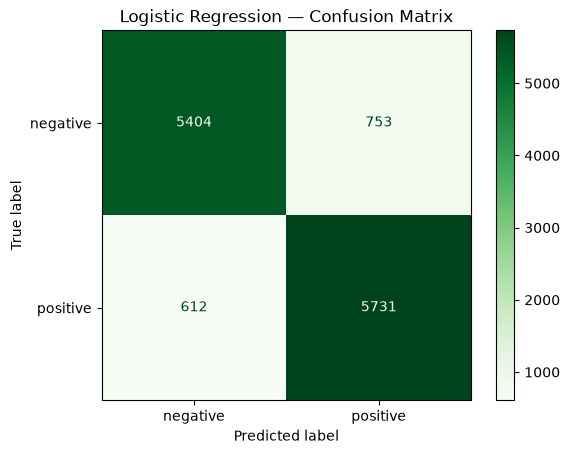

In [31]:
print("Logistic Regression — Classification Report: \n\n", classification_report(y_test, predict_LR))
print("Logistic Regression — Accuracy: \n\n", accuracy_score(y_test, predict_LR))

ConfusionMatrixDisplay.from_predictions(y_test, predict_LR, display_labels=["negative", "positive"], cmap="Greens")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

### Logistic Regression — Test on New Sentences

In [32]:
pred_lr = log_clf.predict(test_vector)
pred_lr_proba = log_clf.predict_proba(test_vector)

for sentence, pred, proba in zip(test_sentences, pred_lr, pred_lr_proba):
    print("Review:", sentence[:70], "..." if len(sentence) > 70 else "")
    print("Logistic Regression prediction:", "Positive" if pred == 1 else "Negative",
          f"(P(positive) = {proba[1]:.3f})")
    print()

Review: I really loved this movie, it was amazing! 
Logistic Regression prediction: Positive (P(positive) = 0.763)

Review: I had really high expectations for this movie, but it turned out to be ...
Logistic Regression prediction: Negative (P(positive) = 0.166)



## 6. Naive Bayes vs Logistic Regression — Quick Comparison

,Model,Accuracy
0,Naive Bayes,0.86024
1,Logistic Regression,0.89080


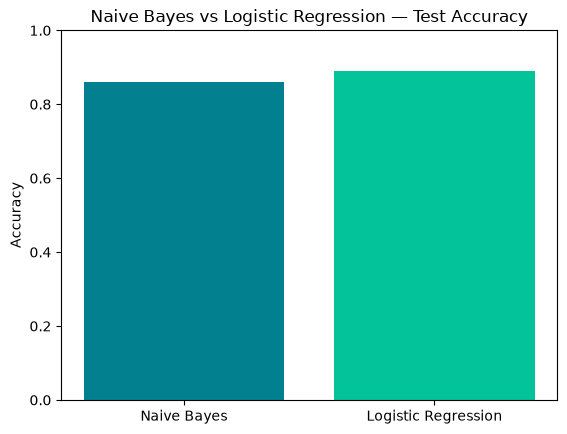

In [33]:
comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, predict_NB), accuracy_score(y_test, predict_LR)]
})
display(comparison)

plt.bar(comparison["Model"], comparison["Accuracy"], color=["#028090", "#02C39A"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Naive Bayes vs Logistic Regression — Test Accuracy")
plt.show()